<a href="https://colab.research.google.com/github/jluzande/computer-vision-projects/blob/main/lab3_histogram.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

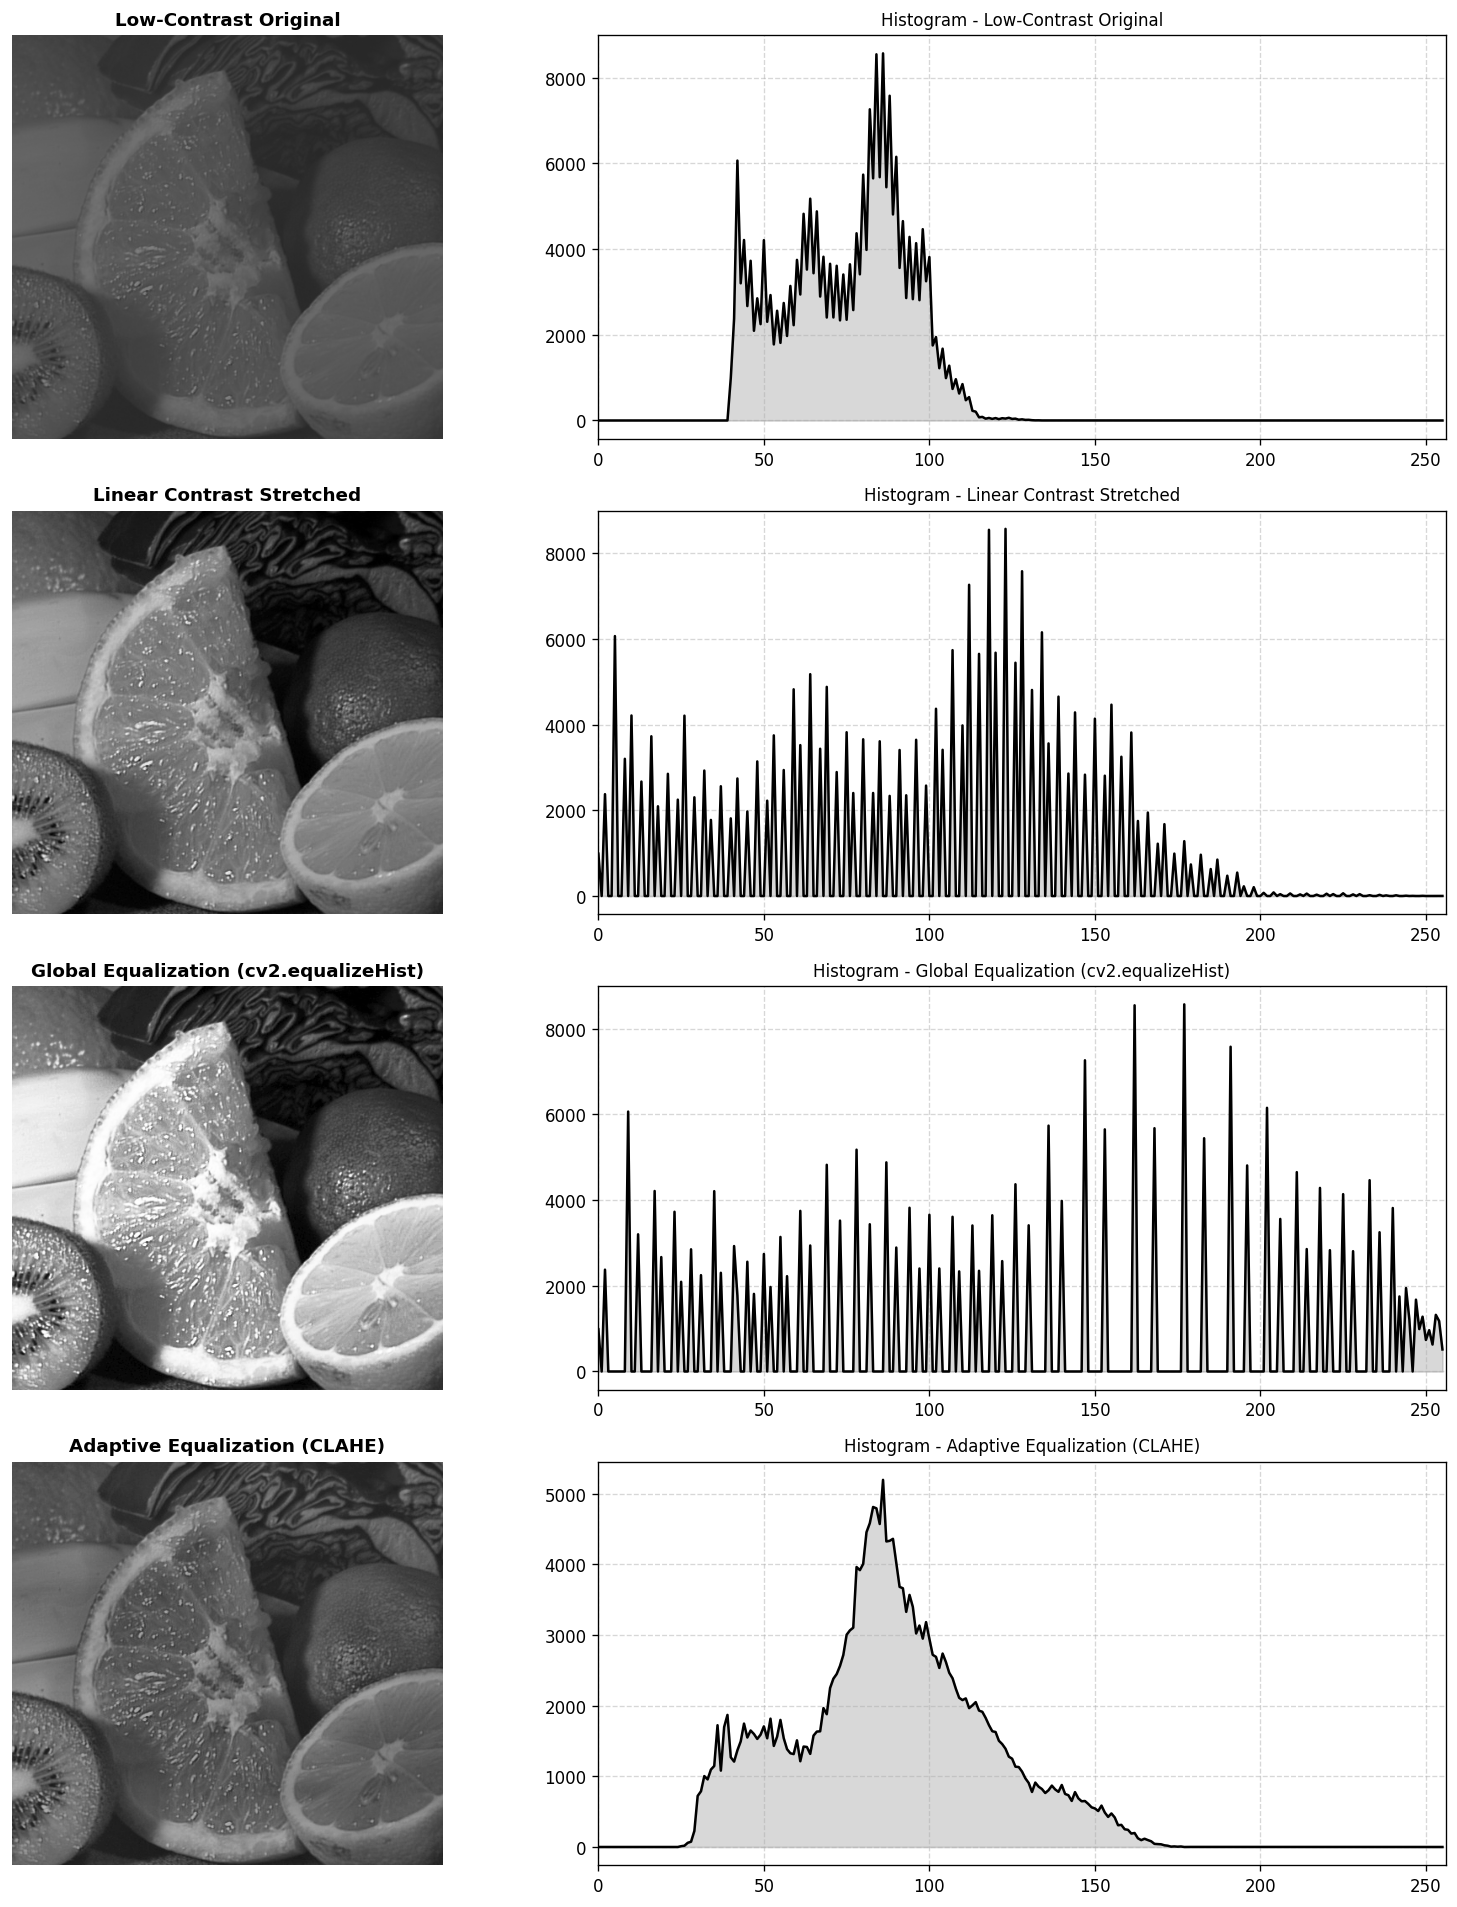

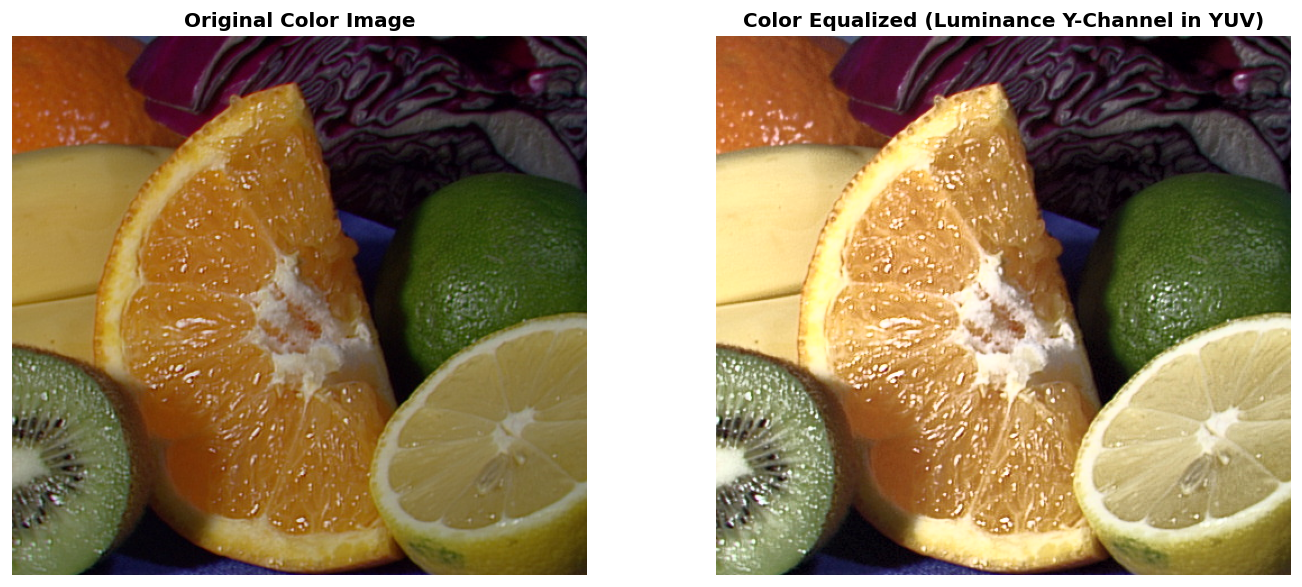

Execution finished. Output images saved for report documentation.


In [ ]:
# ==============================================================================
# CSST106 - Laboratory Exercise: Histogram Equalization and Contrast Adjustment
# Google Colab Compatible Script
# ==============================================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request
import os

# ------------------------------------------------------------------------------
# 1. SETUP: Load a low-contrast sample image
# ------------------------------------------------------------------------------
image_path = "sample_low_contrast.jpg"

if not os.path.exists(image_path):
    print("Downloading sample low-contrast image...")
    # Downloading an underexposed/low-contrast image sample from OpenCV repository
    sample_url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/fruits.jpg"
    urllib.request.urlretrieve(sample_url, image_path)

# Load as color (BGR) and grayscale
img_color = cv2.imread(image_path)
img_gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)

# Intentionally compress dynamic range if image is already high contrast
# to clearly demonstrate the contrast enhancement pipeline
img_gray_low = np.clip(0.4 * img_gray + 40, 0, 255).astype(np.uint8)

# ------------------------------------------------------------------------------
# PART 1: GLOBAL HISTOGRAM EQUALIZATION
# ------------------------------------------------------------------------------
# Grayscale Global Equalization
equalized_gray = cv2.equalizeHist(img_gray_low)

# Color Image Equalization:
# Equalize only the Luminance (Y) channel in YUV space to preserve original chroma
img_yuv = cv2.cvtColor(img_color, cv2.COLOR_BGR2YUV)
img_yuv[:, :, 0] = cv2.equalizeHist(img_yuv[:, :, 0])
equalized_color = cv2.cvtColor(img_yuv, cv2.COLOR_YUV2BGR)

# ------------------------------------------------------------------------------
# PART 2: CONTRAST ADJUSTMENT & CLAHE
# ------------------------------------------------------------------------------
# 1. Linear Contrast Stretching (Min-Max Normalization to [0, 255])
min_val = np.min(img_gray_low)
max_val = np.max(img_gray_low)
stretched_gray = ((img_gray_low - min_val) / (max_val - min_val) * 255.0).astype(np.uint8)

# 2. Contrast Limited Adaptive Histogram Equalization (CLAHE)
# clipLimit limits noise amplification; tileGridSize splits image into localized grids
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
clahe_gray = clahe.apply(img_gray_low)

# ------------------------------------------------------------------------------
# VISUALIZATION 1: GRAYSCALE COMPARISON & HISTOGRAMS
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(4, 2, figsize=(14, 16), dpi=120)

images = [
    ("Low-Contrast Original", img_gray_low),
    ("Linear Contrast Stretched", stretched_gray),
    ("Global Equalization (cv2.equalizeHist)", equalized_gray),
    ("Adaptive Equalization (CLAHE)", clahe_gray)
]

for idx, (title, img) in enumerate(images):
    # Plot image
    axes[idx, 0].imshow(img, cmap='gray', vmin=0, vmax=255)
    axes[idx, 0].set_title(title, fontsize=11, fontweight='bold')
    axes[idx, 0].axis('off')

    # Plot corresponding histogram
    hist = cv2.calcHist([img], [0], None, [256], [0, 256])
    axes[idx, 1].plot(hist, color='black', linewidth=1.5)
    axes[idx, 1].fill_between(range(256), hist.ravel(), color='gray', alpha=0.3)
    axes[idx, 1].set_xlim([0, 256])
    axes[idx, 1].set_title(f"Histogram - {title}", fontsize=10)
    axes[idx, 1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("grayscale_contrast_comparison.png", bbox_inches='tight')
plt.show()

# ------------------------------------------------------------------------------
# VISUALIZATION 2: COLOR IMAGE EQUALIZATION
# ------------------------------------------------------------------------------
plt.figure(figsize=(12, 5), dpi=120)

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB))
plt.title("Original Color Image", fontweight='bold')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(equalized_color, cv2.COLOR_BGR2RGB))
plt.title("Color Equalized (Luminance Y-Channel in YUV)", fontweight='bold')
plt.axis('off')

plt.tight_layout()
plt.savefig("color_equalization_comparison.png", bbox_inches='tight')
plt.show()

# Save standalone outputs
cv2.imwrite("output_low_contrast.png", img_gray_low)
cv2.imwrite("output_stretched.png", stretched_gray)
cv2.imwrite("output_global_equalized.png", equalized_gray)
cv2.imwrite("output_clahe.png", clahe_gray)
cv2.imwrite("output_color_equalized.png", equalized_color)

print("Execution finished. Output images saved for report documentation.")